<a href="https://colab.research.google.com/github/hamidnaji/watermarking-by-opencv/blob/main/postal_card_quera.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [61]:
!pip install pytesseract


In [86]:
import cv2 as cv
from google.colab import drive
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt
import cv2
import pytesseract

In [71]:

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [126]:
myfiles = files.upload()

Saving Isfahan.jpg to Isfahan (4).jpg
Saving Isfahan2.jpg to Isfahan2 (2).jpg


In [127]:
f_list  = myfiles.keys()

In [128]:
img = cv.imread(f'/content/{next(iter(f_list))}' , cv.IMREAD_UNCHANGED)
source = cv.imread(f'/content/{next(iter(f_list))}' , cv.IMREAD_UNCHANGED)


In [129]:
img.shape


(450, 640, 3)

In [130]:
source.shape

(450, 640, 3)

# **sine correction**

In [131]:

img = img.astype(np.float32)

height, width = img.shape[:2]
x = np.arange(width, dtype=np.float32)

# Estimated pattern for this image
amplitude = 64.0
period = 40.0

stripe = amplitude * np.sin(2 * np.pi * x / period)

# Subtract the stripe from every image row
corrected = img - stripe[None, :, None]

corrected = np.clip(corrected, 0, 255).astype(np.uint8)



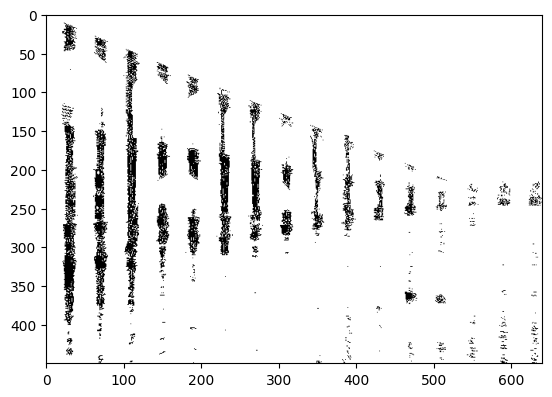

In [132]:
plt.imshow(corrected , cmap='gray')

# **Sine correction and fft within pixel interpolation**

Period: 128.00px; amplitude: 2.30; phase: -2.3805 rad; saved: corrected.png


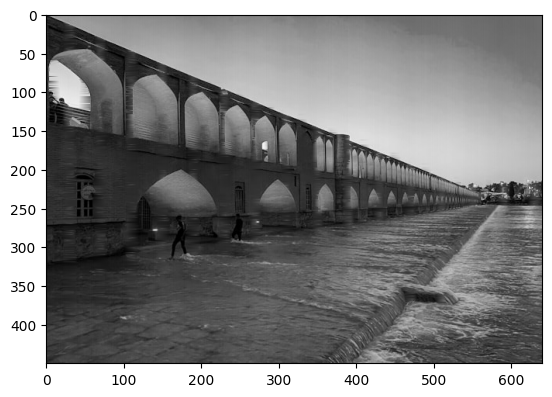

In [144]:

"""Remove regular vertical additive bands from isfahan.jpg.

Requires: pip install opencv-python numpy
Usage: python remove_vertical_stripes.py isfahan.jpg output.png

Assumes a smooth sky area in the top right of this supplied photo.
For other images, adjust sky_x0, sky_x1, sky_y1.
"""
import sys
import cv2
import numpy as np

original = img
if original is None:
    raise FileNotFoundError(source)
height, width = original.shape[:2]
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY).astype(np.float64)

# Find the stripe period from the dominant frequency of the column means.
profile = gray.mean(axis=0)
trend = cv2.GaussianBlur(profile[None, :], (0, 0), sigmaX=35)[0]
spectrum = np.abs(np.fft.rfft(profile - trend))
spectrum[:3] = 0  # Ignore slowly varying photographic brightness.
frequency_bin = int(np.argmax(spectrum))
period = width / frequency_bin

# Fit amplitude and phase over a smooth sky patch (tailored to this image).
sky_x0, sky_x1, sky_y1 = 400, 600, 60
x_fit = np.arange(sky_x0, sky_x1, dtype=np.float64)
y_fit = np.median(gray[:sky_y1, sky_x0:sky_x1], axis=0)
z = (x_fit - x_fit.mean()) / 100.0
basis = np.column_stack([
    np.ones_like(z), z, z*z,
    np.sin(2*np.pi*x_fit/period),
    np.cos(2*np.pi*x_fit/period),
])
coeff = np.linalg.lstsq(basis, y_fit, rcond=None)[0]
a_sin, a_cos = coeff[-2:]
amplitude = float(np.hypot(a_sin, a_cos))
phase = float(np.arctan2(a_cos, a_sin))

# Undo additive stripe signal in each channel.
x = np.arange(width, dtype=np.float64)
wave = amplitude * np.sin(2*np.pi*x/period + phase)
corrected = original.astype(np.float64) - wave[None, :, None]

# Pixels clipped to zero/255 before subtraction have already lost information.
# Estimate these values from neighbors along the same horizontal row.
restored = corrected.copy()
for channel in range(3):
    for row in range(height):
        observed = original[row, :, channel]
        lost = ((observed >= 254) & (wave > 3)) | ((observed <= 1) & (wave < -3))
        known = ~lost
        if known.sum() > 2 and lost.any():
            restored[row, lost, channel] = np.interp(
                x[lost], x[known], corrected[row, known, channel]
            )

out = np.clip(restored, 0, 255).astype(np.uint8)
plt.imshow(out)
print(f"Period: {period:.2f}px; amplitude: {amplitude:.2f}; "
      f"phase: {phase:.4f} rad; saved: {destination}")

In [134]:
out.shape

(450, 640, 3)

# **ocr**

In [135]:


# Read the image with the text and run OCR


In [136]:
gray = cv2.cvtColor(source, cv2.COLOR_BGR2GRAY)
_, clean = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)


error: OpenCV(5.0.0) :-1: error: (-5:Bad argument) in function 'cvtColor'
> Overload resolution failed:
>  - src is not a numpy array, neither a scalar
>  - Expected Ptr<cv::UMat> for argument 'src'


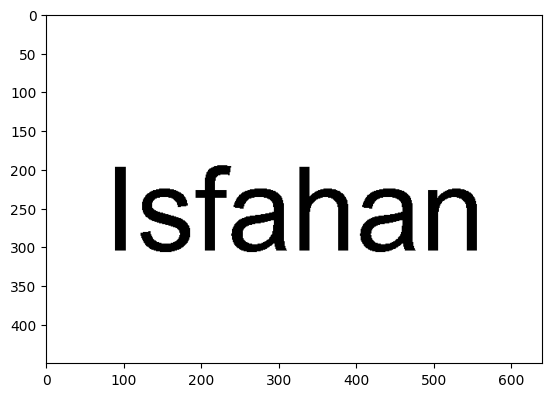

In [137]:
plt.imshow(clean , cmap='gray')

In [138]:
np.unique(clean)

array([  0, 255], dtype=uint8)

In [139]:

text = pytesseract.image_to_string(clean, config="--psm 6").strip()
print(text)  # Isfahan


Isfahan


In [140]:
# cover.shape
# font = cv2.FONT_HERSHEY_SIMPLEX
# scale = 5.0
# thickness= 1

In [141]:

# cv2.putText(
#     out, text, (200, 200), font, scale,
#     (255, 255, 255), thickness, cv2.LINE_AA
# )

# **adding text to cover image**

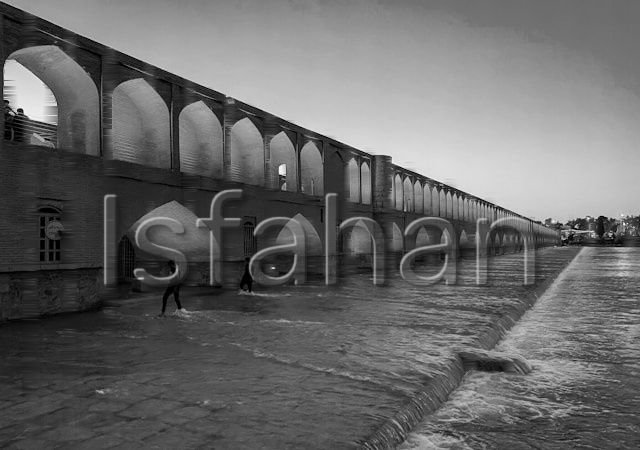

In [142]:
import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow

# Upload your original photo
# img = cv.imread('/content/drive/MyDrive/ai/myprojects/postal card quera/Kish.jpg' , cv.IMREAD_UNCHANGED)
img = out
if img is None:
    raise ValueError("Please upload a valid image.")

# Settings
TEXT = text
WIDTH = 0.02         # Text width relative to image width
FILL_OPACITY = 0.30   # Lower = more transparent inside
EDGE_OPACITY = 0.5  # Higher = stronger embossed edges

h, w = img.shape[:2]
font = cv2.FONT_HERSHEY_SIMPLEX
# thickness = max(2, round(w / 64))
thickness = 1

# Draw centered text into a grayscale mask
base_width = cv2.getTextSize(TEXT, font, 1, thickness)[0][0]
# scale = WIDTH * w / base_width
scale = 4.5
(tw, th), _ = cv2.getTextSize(TEXT, font, scale, thickness)

mask = np.zeros((h, w), dtype=np.uint8)
cv2.putText(
    mask, TEXT, ((w - tw) // 2, (h + th) // 2),
    font, scale, 255, thickness, cv2.LINE_AA
)
mask = mask.astype(np.float32) / 255.0

def shift(layer, dx, dy):
    matrix = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(
        layer, matrix, (w, h),
        borderMode=cv2.BORDER_CONSTANT, borderValue=0
    )

def blend(image, color, opacity):
    alpha = np.clip(opacity, 0, 1)[..., None]
    return image * (1 - alpha) + color * alpha

# Create the bevel from slightly shifted copies of the mask
depth = max(1, round(w / 320))
highlight = np.clip(mask - shift(mask, depth, depth), 0, 1)
shade = np.clip(mask - shift(mask, -depth, -depth), 0, 1)

highlight = cv2.GaussianBlur(highlight, (0, 0), 0.6)
shade = cv2.GaussianBlur(shade, (0, 0), 0.6)

# Soft shadow outside the letters
shadow = cv2.GaussianBlur(
    shift(mask, depth * 2, depth * 2),
    (0, 0), depth * 1.5
)
shadow *= (1 - mask)

# Combine the layers
result = img.astype(np.float32)
result = blend(result, 0, shadow * 0.30)
result = blend(result, 127, mask * FILL_OPACITY)
result = blend(result, 255, highlight * EDGE_OPACITY)
result = blend(result, 0, shade * EDGE_OPACITY)
result = np.clip(result, 0, 255).astype(np.uint8)

cv2_imshow(result)


In [122]:
result.shape

(450, 640, 3)

In [146]:
cv.imwrite('result.jpg' , result)

True

# final function **bold text**

In [143]:
import cv2
import numpy as np
import sys
def apply_watermark(cover_name, message_name):
  img = cv.imread(cover_name , cv.IMREAD_UNCHANGED)
  source = cv.imread(message_name, cv.IMREAD_UNCHANGED)


  #correction




  original = img
  if original is None:
      raise FileNotFoundError(source)
  height, width = original.shape[:2]
  gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY).astype(np.float64)

  # Find the stripe period from the dominant frequency of the column means.
  profile = gray.mean(axis=0)
  trend = cv2.GaussianBlur(profile[None, :], (0, 0), sigmaX=35)[0]
  spectrum = np.abs(np.fft.rfft(profile - trend))
  spectrum[:3] = 0  # Ignore slowly varying photographic brightness.
  frequency_bin = int(np.argmax(spectrum))
  period = width / frequency_bin

  # Fit amplitude and phase over a smooth sky patch (tailored to this image).
  sky_x0, sky_x1, sky_y1 = 400, 600, 60
  x_fit = np.arange(sky_x0, sky_x1, dtype=np.float64)
  y_fit = np.median(gray[:sky_y1, sky_x0:sky_x1], axis=0)
  z = (x_fit - x_fit.mean()) / 100.0
  basis = np.column_stack([
      np.ones_like(z), z, z*z,
      np.sin(2*np.pi*x_fit/period),
      np.cos(2*np.pi*x_fit/period),
  ])
  coeff = np.linalg.lstsq(basis, y_fit, rcond=None)[0]
  a_sin, a_cos = coeff[-2:]
  amplitude = float(np.hypot(a_sin, a_cos))
  phase = float(np.arctan2(a_cos, a_sin))

  # Undo additive stripe signal in each channel.
  x = np.arange(width, dtype=np.float64)
  wave = amplitude * np.sin(2*np.pi*x/period + phase)
  corrected = original.astype(np.float64) - wave[None, :, None]

  # Pixels clipped to zero/255 before subtraction have already lost information.
  # Estimate these values from neighbors along the same horizontal row.
  restored = corrected.copy()
  for channel in range(3):
      for row in range(height):
          observed = original[row, :, channel]
          lost = ((observed >= 254) & (wave > 3)) | ((observed <= 1) & (wave < -3))
          known = ~lost
          if known.sum() > 2 and lost.any():
              restored[row, lost, channel] = np.interp(
                  x[lost], x[known], corrected[row, known, channel]
              )

  out = np.clip(restored, 0, 255).astype(np.uint8)


  #ocr


  gray = cv2.cvtColor(source, cv2.COLOR_BGR2GRAY)
  _, clean = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
  text = pytesseract.image_to_string(clean, config="--psm 6").strip()


  #add text

  img = out
  if img is None:
      raise ValueError("Please upload a valid image.")

  # Settings
  TEXT = text
  WIDTH = 0.02         # Text width relative to image width
  FILL_OPACITY = 0.30   # Lower = more transparent inside
  EDGE_OPACITY = 0.5  # Higher = stronger embossed edges

  h, w = img.shape[:2]
  font = cv2.FONT_HERSHEY_SIMPLEX
  # thickness = max(2, round(w / 64))
  thickness = 1

  # Draw centered text into a grayscale mask
  base_width = cv2.getTextSize(TEXT, font, 1, thickness)[0][0]
  # scale = WIDTH * w / base_width
  scale = 4.5
  (tw, th), _ = cv2.getTextSize(TEXT, font, scale, thickness)

  mask = np.zeros((h, w), dtype=np.uint8)
  cv2.putText(
      mask, TEXT, ((w - tw) // 2, (h + th) // 2),
      font, scale, 255, thickness, cv2.LINE_AA
  )
  mask = mask.astype(np.float32) / 255.0

  def shift(layer, dx, dy):
      matrix = np.float32([[1, 0, dx], [0, 1, dy]])
      return cv2.warpAffine(
          layer, matrix, (w, h),
          borderMode=cv2.BORDER_CONSTANT, borderValue=0
      )

  def blend(image, color, opacity):
      alpha = np.clip(opacity, 0, 1)[..., None]
      return image * (1 - alpha) + color * alpha

  # Create the bevel from slightly shifted copies of the mask
  depth = max(1, round(w / 320))
  highlight = np.clip(mask - shift(mask, depth, depth), 0, 1)
  shade = np.clip(mask - shift(mask, -depth, -depth), 0, 1)

  highlight = cv2.GaussianBlur(highlight, (0, 0), 0.6)
  shade = cv2.GaussianBlur(shade, (0, 0), 0.6)

  # Soft shadow outside the letters
  shadow = cv2.GaussianBlur(
      shift(mask, depth * 2, depth * 2),
      (0, 0), depth * 1.5
  )
  shadow *= (1 - mask)

  # Combine the layers
  result = img.astype(np.float32)
  result = blend(result, 0, shadow * 0.30)
  result = blend(result, 127, mask * FILL_OPACITY)
  result = blend(result, 255, highlight * EDGE_OPACITY)
  result = blend(result, 0, shade * EDGE_OPACITY)
  result = np.clip(result, 0, 255).astype(np.uint8)

  return result
